# Clasificación de tumores: maligno vs. benigno

**Problema:** a partir de 30 medidas de un tumor, predecir si es maligno o benigno.

**¿Cuál error es el peor?** decir que un tumor maligno es benigno (falso negativo) deja al
paciente sin tratamiento; decir que uno benigno es maligno (falso positivo) solo lleva a
más estudios. Por eso elijo la métrica y el modelo pensando en detectar los malignos.

### 1. Análisis exploratorio de datos (EDA)

In [1]:
from sklearn.datasets import load_breast_cancer

In [2]:
import pandas as pd # sec. 1
from sklearn.model_selection import train_test_split # sec. 2
from sklearn.preprocessing import StandardScaler # sec. 3
from sklearn.linear_model import LogisticRegression # sec. 4
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, roc_auc_score # sec. 5
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay # sec. 6

In [3]:
data = load_breast_cancer(as_frame=True)
X, y  = data.data, data.target

In [4]:
X

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [5]:
y

0      0
1      0
2      0
3      0
4      0
      ..
564    0
565    0
566    0
567    0
568    1
Name: target, Length: 569, dtype: int64

In [6]:
# target: 0 = maligno, 1 = benigno
print(X.shape)
print(y.value_counts(normalize=True).round(2))

(569, 30)
target
1    0.63
0    0.37
Name: proportion, dtype: float64


In [7]:
print(X.isna().sum().sum())

X.describe().T[["mean", "std", "min", "max"]].sort_values("mean")

0


,mean,std,min,max
fractal dimension error,0.003795,0.002646,0.000895,0.02984
smoothness error,0.007041,0.003003,0.001713,0.03113
concave points error,0.011796,0.006170,0.000000,0.05279
symmetry error,0.020542,0.008266,0.007882,0.07895
compactness error,0.025478,0.017908,0.002252,0.13540
concavity error,0.031894,0.030186,0.000000,0.39600
mean concave points,0.048919,0.038803,0.000000,0.20120
mean fractal dimension,0.062798,0.007060,0.049960,0.09744
worst fractal dimension,0.083946,0.018061,0.055040,0.20750
mean concavity,0.088799,0.079720,0.000000,0.42680


#### Lo que encontré
- 569 tumores, 30 medidas, sin valores faltantes.
- 212 malignos (37 %) y 357 benignos (63 %). Un modelo que siempre diga «benigno»
  tendría 63 % de accuracy sin detectar ningún maligno: por eso el accuracy no basta.
- Las escalas son muy distintas (de ~0.004 a ~880). Los modelos sensibles a la escala
  necesitan estandarizar; los árboles no.

### 2. Partición de datos: entrenamiento, validación y prueba

In [8]:
# Datos (569) ──┬── train 60%  → aprenden los modelos
#               └── temp  40%  ──┬── val   50% → comparo y elijo
#                                └── test  50%  → solo al final



#Conjunto	    %	Función

# Train	      60%	Entrenar el modelo (ajustar parámetros)
# Validation  20%	Ajustar hiperparámetros / elegir modelo / early stopping
# Test	      20%	Evaluación final honesta (nunca se toca durante el desarrollo)

In [9]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, 
	test_size=0.4, 
	stratify=y, 
	random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, 
	test_size=0.5, 
	stratify=y_temp, 
	random_state=42
)

print(len(X_train), len(X_val), len(X_test))

341 114 114


### 3. Preprocesamiento

In [10]:
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print(X_train_s.mean().round(2), X_train_s.std().round(2))

-0.0 1.0


### 4. Entrenamiento de modelos

In [11]:
models = {
	"Logistic Regression": (LogisticRegression(max_iter=1_000), X_train_s, X_val_s),
	"KNN": (KNeighborsClassifier(n_neighbors=5), X_train_s, X_val_s),
	"Random Forest": (RandomForestClassifier(random_state=42), X_train, X_val)
}

In [12]:
for name, (model, Xtr, Xv) in models.items():
	model.fit(Xtr, y_train)
	print(f"Modelo {name} Entrenado ")

Modelo Logistic Regression Entrenado 
Modelo KNN Entrenado 
Modelo Random Forest Entrenado 


### 5. Selección del modelo

In [13]:
rows = []
for name, (model, Xtr, Xv) in models.items():
	pred_val = model.predict(Xv)
	rows.append({
		"model": name,
		"accuracy train": accuracy_score(y_train, model.predict(Xtr)),
		"accuracy val": accuracy_score(y_val, pred_val),
		"recall maligno val": recall_score(y_val, pred_val, pos_label=0),
		"falsos negativos val": ((y_val == 0) & (pred_val == 1)).sum(),
		"AUC val": roc_auc_score(y_val, model.predict_proba(Xv)[:, 1])
	})

pd.DataFrame(rows).set_index("model").round(3)

,accuracy train,accuracy val,recall maligno val,falsos negativos val,AUC val
model,,,,,
Logistic Regression,0.985,0.991,1.000,0,1.000
KNN,0.971,0.974,0.952,2,0.998
Random Forest,1.000,0.965,0.929,3,0.997


#### Decisión
Elijo la **regresión logística**:
- Es la única sin falsos negativos en validación (recall de malignos = 1.0). Su único
  error fue un benigno marcado como maligno, el error menos grave.
- AUC de 1.0: separa las clases mejor que los otros dos.
- No muestra overfitting (train 0.985, val 0.991). El bosque sí: 1.000 en train
  contra 0.965 en val.
- Es la más simple y explicable: cada variable tiene un peso.

### 6. Evaluación final

In [14]:
best = models["Logistic Regression"][0]
pred_test = best.predict(X_test_s)

_class = classification_report(
	y_true=y_test, 
	y_pred=pred_test,
	target_names=["maligno", "benigno"],
	digits=4,
)
_roc = roc_auc_score(
	y_true=y_test,
	y_score=best.predict_proba(X_test_s)[:, 1]
	)
print(_class)
print("AUC test:", round(_roc, 3))

              precision    recall  f1-score   support

     maligno     1.0000    0.9767    0.9882        43
     benigno     0.9861    1.0000    0.9930        71

    accuracy                         0.9912       114
   macro avg     0.9931    0.9884    0.9906       114
weighted avg     0.9913    0.9912    0.9912       114

AUC test: 0.997


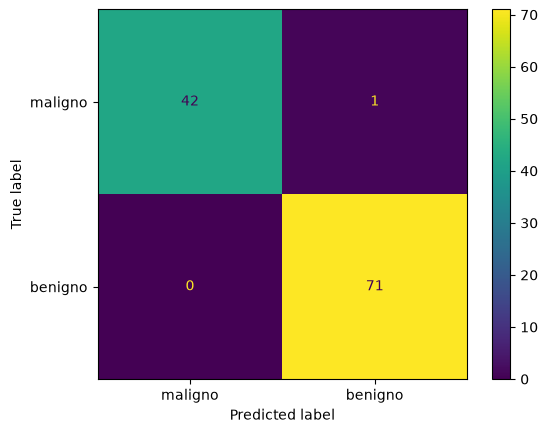

In [15]:
ConfusionMatrixDisplay.from_predictions(
	y_test,
	pred_test,
	display_labels=["maligno", "benigno"]
)

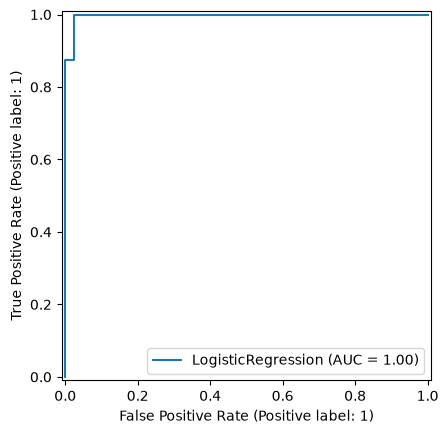

In [16]:
RocCurveDisplay.from_estimator(
	best,
	X_test_s,
	y_test
)

#### Conclusión
- En prueba (114 casos nunca vistos): accuracy 0.991, AUC 0.997.
- Detectó 42 de 43 malignos (recall 0.977). El único error fue un falso negativo,
  el error grave. No hubo falsas alarmas (precision de maligno 1.0).
- En validación no tuvo falsos negativos y en prueba sí: validación es optimista porque
  con ella elegí el modelo; la cifra honesta es esta.
- Mejora posible: bajar el umbral de decisión para marcar maligno con menos certeza.
  Detectaría más malignos a cambio de algunas falsas alarmas, que solo llevan a más
  estudios. Ese umbral se ajustaría en validación, no en prueba.

#### Respuestas a las preguntas

**1. ¿Cómo funciona cada uno de los modelos que usaste y en qué se diferencian?**

La regresión logística traza una frontera lineal: suma las variables con un peso cada una
y convierte el resultado en probabilidad. KNN no aprende pesos: clasifica por votación de
los 5 tumores más parecidos (por distancia), por eso necesita escalar. El bosque aleatorio
entrena muchos árboles de decisión, cada uno con una muestra distinta, y votan; corta por
umbrales, por eso no le importa la escala.

**2. ¿Qué es el overfitting y qué es el underfitting? ¿Viste señales de alguno en tus modelos?**

Overfitting es memorizar el entrenamiento: va muy bien en train y peor en datos nuevos.
Underfitting es no captar el patrón: va mal en ambos. El bosque mostró overfitting
(1.000 en train, 0.965 en val). Ninguno mostró underfitting: los tres pasan de 0.97 en train.

**3. ¿Con qué métrica estás midiendo el performance?**

Con el recall de la clase maligna, porque mide cuántos malignos detecto, y dejar escapar
uno es el error que más cuesta. El AUC es la segunda.

**4. ¿Por qué no basta con reportar el accuracy?**

Un modelo que siempre dijera «benigno» tendría 63 % de accuracy sin detectar ningún
maligno. Además, el accuracy no distingue entre los dos errores: un falso negativo y un
falso positivo cuentan igual, y aquí no cuestan igual.

**5. Explica la matriz de confusión, las métricas usadas y el AUC.**

Matriz de confusión: filas = clase real, columnas = predicción. Lo grave está en
«real maligno, predijo benigno» (falso negativo). Precision: de los que marqué malignos,
cuántos lo eran. Recall: de los malignos reales, cuántos detecté. F1 combina las dos.
AUC: área bajo la curva ROC, que muestra aciertos frente a falsas alarmas al mover el
umbral. Mide qué tan bien ordena el modelo sin depender del umbral: 1 = separa perfecto,
0.5 = azar.